In [1]:
# 09 · Hazırlık: ön koşullar + 08 kayıtları + 08'deki değerlendirme fonksiyonları
import os, sys, json
from pathlib import Path
from collections import Counter
import requests

KOK = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(KOK))
from src import ayarlar, llm

# 1) DeepSeek
print("DEEPSEEK_API_KEY:", "VAR" if os.getenv("DEEPSEEK_API_KEY") else "YOK")
try:
    print("DeepSeek modelleri:", [m.id for m in llm.istemci("deepseek-chat").models.list()])
except Exception as e:
    print("DeepSeek HATA:", e)

# 2) Ollama: qwen2.5:7b yüklü mü, bağlam penceresi kaç
etiketler = [m["name"] for m in requests.get(f"{ayarlar.OLLAMA_URL}/api/tags", timeout=10).json()["models"]]
print("Ollama modelleri:", etiketler)
if "qwen2.5:7b" in etiketler:
    r = llm.sohbet("qwen2.5:7b", [{"role": "user", "content": "Sadece 'tamam' yaz."}])
    print("qwen cevap:", r.choices[0].message.content)
    for m in requests.get(f"{ayarlar.OLLAMA_URL}/api/ps", timeout=10).json()["models"]:
        print("yüklü:", m["name"], "| bağlam:", m.get("context_length", "bilgi yok"),
              "| VRAM GB:", round(m.get("size_vram", 0) / 1e9, 1))

# 3) 08'de hangi kayıtlar var
def oku(yol):
    return [json.loads(s) for s in open(yol, encoding="utf-8") if s.strip()]

cal = oku(KOK / "reports/08_calistirmalar.jsonl")
hak = oku(KOK / "reports/08_hakem.jsonl")
print(f"\n{len(cal)} çalıştırma | alanlar: {list(cal[0].keys())}")
for k, n in sorted(Counter(str((c.get("model"), c.get("deney", "v4"), c.get("metin_modu"), c.get("tekrar"))) for c in cal).items()):
    print("  ", k, n)
print(f"\n{len(hak)} hakem | alanlar: {list(hak[0].keys())}")
for k, n in sorted(Counter(str((h.get("model"), h.get("deney", "v4"), h.get("metin_modu"), h.get("tekrar"), h.get("hakem_surum"))) for h in hak).items()):
    print("  ", k, n)

# 4) 08 notebook'undaki değerlendirme fonksiyonlarının SON hâlleri
nb = json.load(open(KOK / "notebooks/08_degerlendirme.ipynb", encoding="utf-8"))
hucreler = ["".join(h["source"]) for h in nb["cells"] if h["cell_type"] == "code"]
ARANAN = ["def bir_calistirma", "def arac_dogru", "def tr_sayi", "def supheli_sayilar", "SABIT_HAVUZ =",
          "def hakem_mesaji", "HAKEM_TALIMATI =", "def hakem", "FIYAT =", "ESKI_AD ="]
secilen = []
for a in ARANAN:
    son = max((i for i, h in enumerate(hucreler) if a in h), default=None)
    print(f"{a!r} → hücre {son}")
    if son is not None and son not in secilen:
        secilen.append(son)
for i in sorted(secilen):
    print(f"\n{'=' * 25} 08 kod hücresi {i} {'=' * 25}\n{hucreler[i]}")

DEEPSEEK_API_KEY: VAR
DeepSeek modelleri: ['deepseek-flash', 'deepseek-v4-pro']
Ollama modelleri: ['qwen2.5:7b', 'qwen3-embedding:0.6b', 'qwen3-embedding:4b', 'bge-m3:latest']
qwen cevap: Tamam
yüklü: qwen2.5:7b | bağlam: 4096 | VRAM GB: 4.8

270 çalıştırma | alanlar: ['id', 'kategori', 'tekrar', 'model', 'metin_modu', 'talimat_kar', 'soru', 'cevap', 'arac_adlari', 'araclar', 'arac_hata', 'tur', 'sure', 'girdi_token', 'cikti_token', 'maliyet_usd', 'arac_ciktilari', 'zaman', 'hata']
   ('gpt-4.1-mini', 'v4', 'gizle', 1) 30
   ('gpt-4.1-mini', 'v4', 'gizle', 2) 30
   ('gpt-4.1-mini', 'v4', 'gizle', 3) 30
   ('gpt-4.1-mini', 'v5', 'gizle', 1) 30
   ('gpt-4.1-mini', 'v5', 'kes', 1) 30
   ('gpt-6-luna', 'v4', 'gizle', 1) 30
   ('gpt-6-luna', 'v4+ipucu', 'gizle', 1) 30
   ('gpt-6-luna', 'v5', 'gizle', 1) 30
   ('gpt-6-luna', 'v5', 'kes', 1) 30

330 hakem | alanlar: ['id', 'model', 'tekrar', 'metin_modu', 'hakem_model', 'hakem_surum', 'puan', 'uydurma', 'kural_ihlali', 'gerekce', 'hakem_maliy

In [2]:
# 09 · Adım 1: hakem talimatı v3'ü dondur + degerlendirme modülü + DeepSeek/qwen deneme
import ast, importlib

# (a) 08'deki HAKEM_TALIMATI'nın son hâlini, o notebook'taki atamaları sırayla yeniden çalıştırarak kur
nb = json.load(open(KOK / "notebooks/08_degerlendirme.ipynb", encoding="utf-8"))
kodlar = ["".join(h["source"]) for h in nb["cells"] if h["cell_type"] == "code"]
alan = {}
for i, kod in enumerate(kodlar):
    if "HAKEM_TALIMATI" not in kod:
        continue
    try:
        govde = ast.parse(kod).body
    except SyntaxError:
        print(f"hücre {i}: ayrıştırılamadı, atlandı")
        continue
    for dugum in govde:
        parca = ast.get_source_segment(kod, dugum)
        sabit_atama = isinstance(dugum, ast.Assign) and not any(isinstance(n, ast.Name) for n in ast.walk(dugum.value))
        talimat_satiri = "HAKEM_TALIMATI" in parca and isinstance(dugum, (ast.Assign, ast.AugAssign, ast.If, ast.Assert))
        if sabit_atama or talimat_satiri:
            try:
                exec(parca, alan)
            except Exception as e:
                print(f"hücre {i}: atlandı ({type(e).__name__}) → {parca[:70]!r}")
T = alan["HAKEM_TALIMATI"]
assert "oyun_oner" in T, "son düzeltme (oyun_oner) uygulanmamış"
(KOK / "reports/hakem_talimati_v3.txt").write_text(T, encoding="utf-8")
print(f"Hakem talimatı: {len(T)} karakter · sürüm {alan.get('HAKEM_SURUM')}\n{'-' * 80}\n{T}\n{'-' * 80}")

# (b) yeni llm.py + degerlendirme modülü
importlib.reload(llm)
from src import degerlendirme as d
importlib.reload(d)
print(f"\nSoru: {len(d.SORULAR)} · talimat: {len(d.SISTEM_TALIMATI)} kar. · METIN_MODU: {ayarlar.METIN_MODU}")

# (c) deneme: 2 soru × 2 model, kaydedilmez
for model in ["deepseek-flash", "qwen2.5:7b"]:
    for sid in ["S1", "K1"]:
        k = d.bir_calistirma(d.SORU[sid], 0, model, "deneme")
        print(f"\n{'=' * 90}\n[{sid}] {model} · tur {k['tur']} · {k['sure']} sn · token {k['girdi_token']}+{k['cikti_token']}"
              f" · ${k['maliyet_usd']} · araç hatası {k['arac_hata']} · tekrar engeli {k['tekrar_engel']}")
        print(f"SORU: {k['soru']}\nARAÇLAR: {k['araclar']}\nCEVAP:\n{k['cevap']}")
for m in requests.get(f"{ayarlar.OLLAMA_URL}/api/ps", timeout=10).json()["models"]:
    print(f"\nOllama yüklü: {m['name']} | bağlam: {m.get('context_length')} | VRAM GB: {round(m.get('size_vram', 0) / 1e9, 1)}")

hücre 12: atlandı (NameError) → 'FIYAT["gpt-6.1-terra"] = (2.00, 10.00)'
Hakem talimatı: 2627 karakter · sürüm v3
--------------------------------------------------------------------------------
Sen bir LLM agent'ının cevaplarını puanlayan titiz bir değerlendiricisin. Agent Steam oyun verisi üzerinde Türkçe soru cevaplıyor; araçları: oyun_bul, sql_calistir (SQLite), yorum_ara (oyuncu yorumları), oyun_oner (tarife göre oyun; eski kayıtlarda adı oyun_ara).

Sana verilecekler: kullanıcı sorusu, doğru sayılma şartı (KONTROL), beklenen araçlar, bizim hesapladığımız REFERANS, agent'ın çağırdığı araçlar ve gördüğü ARAÇ ÇIKTILARI, agent'ın CEVABI ve agent'ın uyması gereken SİSTEM TALİMATI.

Puan:
2 = Doğru ve eksiksiz. KONTROL şartının tamamı tutuyor, cevaptaki iddialar araç çıktılarına dayanıyor, talimat kuralları uygulanmış. Biçim ve üslup farkları puan düşürmez.
1 = Kısmen doğru. Ana cevap doğru ama KONTROL şartının bir kısmı eksik (gerekli bir uyarı, bağlam ya da aday eksik) veya küçük bir

/home/kaan/steam-oyun-asistani/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Soru: 30 · talimat: 3703 kar. · METIN_MODU: gizle

[S1] deepseek-flash · tur 2 · 2.7 sn · token 11677+112 · $0.00182 · araç hatası 0 · tekrar engeli 0
SORU: Baldur's Gate 3'ün Steam puanı ve oy sayısı nedir?
ARAÇLAR: ['oyun_bul({"isim": "Baldur\'s Gate 3"})']
CEVAP:
**Baldur's Gate 3** (app_id 1086940): Steam oylarına göre olumlu oran **%96,8** ve toplam **669.941** oy var.

Kaynak: oyun_bul sonucu (Steam oy verisi).

[K1] deepseek-flash · tur 3 · 31.2 sn · token 19362+599 · $0.00326 · araç hatası 0 · tekrar engeli 0
SORU: The Sims 4'ü oyuncular seviyor mu?
ARAÇLAR: ['oyun_bul({"isim": "The Sims 4"})', 'sql_calistir({"sorgu": "SELECT ad, olumlu_oran, oy_sayisi, yorum_sayisi, yorum_kapsami, fiyat, normal_fiyat FROM oyunlar WHERE app_id = 1222670"})', 'yorum_ara({"mod": "ozetle", "app_id": 1222670})']
CEVAP:
**Kısaca: Evet, oyuncular oyunun kendisini seviyor — ama DLC fiyatlandırmasından çok şikâyetçiler.**

Steam oylarına göre The Sims™ 4'ün genel puanı **%87 olumlu** (153.114 oy). Yan

## Adım 1 · Değerlendirme modülü ve yeni modeller
- 08'deki değerlendirme kodu `src/degerlendirme.py`'ye taşındı (çalıştırma, otomatik kontroller, hakem). Kayıtlar aynı dosyalarda: `reports/08_calistirmalar.jsonl`, `reports/08_hakem.jsonl`.
- Hakem talimatı v3, 08 notebook'undan yeniden kurulup `reports/hakem_talimati_v3.txt`'ye donduruldu.
- **DeepSeek:** `deepseek-chat` adı kalkmış. `deepseek-flash` (DeepSeek-V4.1-Flash-1017) seçildi, düşünme kapalı (Luna ile eşit şart). Fiyat $0,15 / $0,60 (1M token, yoğun olmayan saat).
- **qwen2.5:7b (Ollama):** varsayılan bağlam 4.096 token'dı, istekler 10–18 bin token. `OLLAMA_CONTEXT_LENGTH=32768` ile büyütüldü (VRAM 6,6 GB).
- Deneme (S1, K1): DeepSeek ikisinde de doğru araç ve doğru cevap verdi (K1 31 sn). qwen S1'de puanı uydurdu (%88,5, doğrusu %96,8), K1'de yorumlara bakmadı.

In [3]:
# 09 · Adım 2: eksik çalıştırmalar (v5, gizle, 3 tekrar) + otomatik kontroller
print(f"Hakem talimatı ({len(d.hakem_talimati())} kar.):\n{d.hakem_talimati()}\n{'=' * 90}")

MODELLER = ["gpt-4.1-mini", "gpt-6-luna", "deepseek-flash", "qwen2.5:7b"]
for model in MODELLER:
    d.hepsini_calistir(model, tekrarlar=(1, 2, 3), deney="v5")

df = d.kontrolleri_ekle(d.sonuclar())
v5 = df[(df["deney"] == "v5") & (df["metin_modu"] == "gizle") & df["model"].isin(MODELLER)]
print("\n== Model özeti (v5, gizle) ==")
display(v5.groupby("model").agg(
    n=("id", "size"), cokme=("hata", lambda x: x.notna().sum()),
    arac_dogru=("arac_dogru", "mean"), supheli_sayili=("supheli_var", "mean"),
    arac_hatali=("arac_hatali", "sum"), tekrar_engel=("tekrar_engel", "sum"),
    tur=("tur", "mean"), sure=("sure", "mean"), sure_max=("sure", "max"),
    maliyet_30_soru=("maliyet_usd", lambda x: x.sum() / 3)).reindex(MODELLER).round(3))
print("\n== Kategori bazında araç doğruluğu ==")
display(v5.pivot_table(index="kategori", columns="model", values="arac_dogru", aggfunc="mean")[MODELLER].round(2))
print("\n== Çöken çalıştırmalar ==")
display(v5[v5["hata"].notna()][["id", "model", "tekrar", "hata"]])

Hakem talimatı (2627 kar.):
Sen bir LLM agent'ının cevaplarını puanlayan titiz bir değerlendiricisin. Agent Steam oyun verisi üzerinde Türkçe soru cevaplıyor; araçları: oyun_bul, sql_calistir (SQLite), yorum_ara (oyuncu yorumları), oyun_oner (tarife göre oyun; eski kayıtlarda adı oyun_ara).

Sana verilecekler: kullanıcı sorusu, doğru sayılma şartı (KONTROL), beklenen araçlar, bizim hesapladığımız REFERANS, agent'ın çağırdığı araçlar ve gördüğü ARAÇ ÇIKTILARI, agent'ın CEVABI ve agent'ın uyması gereken SİSTEM TALİMATI.

Puan:
2 = Doğru ve eksiksiz. KONTROL şartının tamamı tutuyor, cevaptaki iddialar araç çıktılarına dayanıyor, talimat kuralları uygulanmış. Biçim ve üslup farkları puan düşürmez.
1 = Kısmen doğru. Ana cevap doğru ama KONTROL şartının bir kısmı eksik (gerekli bir uyarı, bağlam ya da aday eksik) veya küçük bir hata var, ya da ana cevap doğru ama yan bir iddia araç çıktılarında desteklenmiyor (bu durumda uydurma=true işaretle ama puan 1 ver).
0 = Yanlış. Ana cevap yanlış, so

gpt-4.1-mini: 100%|██████████| 60/60 [03:50<00:00,  3.84s/it]


gpt-6-luna · deney v5 · gizle · yapılacak: 60


gpt-6-luna: 100%|██████████| 60/60 [07:17<00:00,  7.30s/it]


deepseek-flash · deney v5 · gizle · yapılacak: 90


deepseek-flash: 100%|██████████| 90/90 [08:55<00:00,  5.95s/it]


... (4 outputs left out)


== Kategori bazında araç doğruluğu ==


model,gpt-4.1-mini,gpt-6-luna,deepseek-flash,qwen2.5:7b
kategori,,,,
diger,1.00,0.67,1.0,0.67
karma,0.80,1.00,1.0,0.00
oneri,0.93,1.00,1.0,0.00
rag,1.00,0.83,1.0,0.17
sql,1.00,1.00,1.0,0.33
tuzak,1.00,0.87,1.0,0.20



== Çöken çalıştırmalar ==


,id,model,tekrar,hata


## Adım 2 · Çalıştırmalar (v5, gizle, 30 soru × 3 tekrar × 4 model = 360)
| model | araç doğru | şüpheli sayı | tekrar engeli | tur | süre (sn) | $ / 30 soru |
|---|---|---|---|---|---|---|
| gpt-4.1-mini | %96 | %3 | 4 | 2,6 | 3,8 | 0,158 |
| gpt-6-luna | %91 | %0 | **44** | 3,8 | 6,8 | **0,060** |
| deepseek-flash | **%100** | %1 | 0 | 2,6 | 5,9 | 0,086 |
| qwen2.5:7b | %20 | **%33** | 0 | 1,4 | 2,5 | 0 (yerel) |
- Çökme 0.
- DeepSeek araç seçiminde kusursuz.
- Luna'nın tekrar döngüsü 3 tekrarda da sürüyor.
- qwen çoğu soruda araç çağırmadan cevap veriyor; 7B model bu karmaşıklıkta bir agent'ı yürütemiyor.

In [4]:
# 09 · Adım 3: hakem v3 puanlaması + ana tablo
import numpy as np

T = d.hakem_talimati()
assert "oyun_oner" in T and "EK AÇIKLAMA" in T, "hakem talimatı v3 değil!"
print(f"Hakem talimatı v3 ✓ ({len(T)} kar.) — EK AÇIKLAMALAR bölümü:\n{T[T.index('EK AÇIKLAMA'):]}\n")

d.hepsini_puanla(v5)
hk = d.hakem_sonuclari()
m = v5.merge(hk[d.ANAHTAR + ["puan", "uydurma", "kural_ihlali", "gerekce", "hakem_maliyet"]], on=d.ANAHTAR, how="left")
for s in ["puan", "uydurma", "kural_ihlali"]:
    m[s] = m[s].astype(float)
print(f"Puansız cevap: {m['puan'].isna().sum()} · 360 cevabın toplam hakem maliyeti: ${m['hakem_maliyet'].sum():.2f}")

tekrar_ort = m.groupby(["model", "tekrar"])["puan"].mean().unstack().reindex(MODELLER)
ana = m.groupby("model").agg(
    puan=("puan", "mean"), uydurma=("uydurma", "mean"), kural_ihlali=("kural_ihlali", "mean"),
    tam_dogru=("puan", lambda x: (x == 2).mean()), arac_dogru=("arac_dogru", "mean"),
    sure=("sure", "mean"), maliyet_30_soru=("maliyet_usd", lambda x: x.sum() / 3)).reindex(MODELLER)
ana["tekrar_puanlari"] = tekrar_ort.round(2).astype(str).agg(" / ".join, axis=1)
ana["yayilim"] = tekrar_ort.max(axis=1) - tekrar_ort.min(axis=1)
ana["en_iyiye_fark"] = ana["puan"].max() - ana["puan"]
ana["sonuc"] = np.where(ana["en_iyiye_fark"] < 0.15, "en iyiyle eşit", "geride")
print("\n== ANA TABLO (hakem v3, 30 soru × 3 tekrar) ==")
display(ana.round(3))

print("\n== Kategori bazında puan (3 tekrar ortalaması) ==")
display(m.pivot_table(index="kategori", columns="model", values="puan", aggfunc="mean")[MODELLER].round(2))

print("\n== Soru bazında puan (3 tekrar ortalaması, 0–2) ==")
display(m.pivot_table(index="id", columns="model", values="puan", aggfunc="mean")[MODELLER]
         .reindex([s["id"] for s in d.SORULAR]).round(2))

print("\n== Luna: tekrar engelinin devreye girdiği sorular ==")
lt = m[(m["model"] == "gpt-6-luna") & (m["tekrar_engel"] > 0)]
print(lt.groupby("id").agg(calistirma=("tekrar", "size"), engel=("tekrar_engel", "sum"), tur=("tur", "mean"), puan=("puan", "mean")))

Hakem talimatı v3 ✓ (2627 kar.) — EK AÇIKLAMALAR bölümü:
EK AÇIKLAMALAR (puanlarken mutlaka uygula):
- Agent'ın SİSTEM TALİMATI'nda yazan bilgiler (verinin 2020-2024 dönemi, fiyatların $ olması, eşikler) araç çıktısında geçmese de uydurma değildir.
- oyun_bul çıktısında olumlu_oran ve oy_sayisi vardır. Puanı ve oy sayısını oyun_bul'dan vermek doğrudur, ayrıca sql_calistir gerekmez. BEKLENEN ARAÇLAR bir rehberdir: agent farklı araçlarla doğru ve dayanaklı cevap verdiyse puan düşürme. (Hiç araç kullanmadan veri hakkında bilgi vermek ise yine ciddi ihlaldir.)
- Talimatın cevap biçimi oranları yüzde ve yuvarlanmış vermeyi ister (0,874 → %87; 669.941 → yaklaşık 670 bin). Makul yuvarlama hata değildir.
- Kullanıcının alacağı cevabı etkilemeyen küçük biçim kusurları (ör. madde sayısı) puan düşürmez; puan, KONTROL şartına ve cevabın doğruluğuna göre verilir.

Sadece şu JSON'u döndür: {"puan": 0, "uydurma": false, "kural_ihlali": false, "gerekce": "Türkçe, en fazla 2 cümle"}

Hakem: gpt-6.1-ter

hakem: 100%|██████████| 300/300 [18:02<00:00,  3.61s/it]

Puansız cevap: 0 · 360 cevabın toplam hakem maliyeti: $3.50

== ANA TABLO (hakem v3, 30 soru × 3 tekrar) ==


,puan,uydurma,kural_ihlali,tam_dogru,arac_dogru,sure,maliyet_30_soru,tekrar_puanlari,yayilim,en_iyiye_fark,sonuc
model,,,,,,,,,,,
gpt-4.1-mini,1.144,0.389,0.411,0.378,0.956,3.810,0.158,1.07 / 1.23 / 1.13,0.167,0.244,geride
gpt-6-luna,1.389,0.211,0.400,0.500,0.911,6.773,0.060,1.43 / 1.37 / 1.37,0.067,0.000,en iyiyle eşit
deepseek-flash,1.256,0.611,0.478,0.311,1.000,5.868,0.086,1.23 / 1.23 / 1.3,0.067,0.133,en iyiyle eşit
qwen2.5:7b,0.133,0.811,0.944,0.033,0.200,2.501,0.000,0.13 / 0.13 / 0.13,0.000,1.256,geride



== Kategori bazında puan (3 tekrar ortalaması) ==


model,gpt-4.1-mini,gpt-6-luna,deepseek-flash,qwen2.5:7b
kategori,,,,
diger,1.78,0.89,1.67,0.67
karma,0.80,1.53,1.33,0.20
oneri,0.93,1.33,0.93,0.00
rag,1.06,1.06,0.94,0.00
sql,1.33,1.83,1.50,0.00
tuzak,1.20,1.47,1.33,0.20



== Soru bazında puan (3 tekrar ortalaması, 0–2) ==


model,gpt-4.1-mini,gpt-6-luna,deepseek-flash,qwen2.5:7b
id,,,,
S1,2.00,2.00,2.00,0.0
S2,2.00,2.00,2.00,0.0
S3,0.67,1.00,1.00,0.0
S4,0.00,2.00,2.00,0.0
S5,2.00,2.00,2.00,0.0
S6,1.33,2.00,0.00,0.0
R1,1.67,1.67,1.00,0.0
R2,1.00,1.00,1.00,0.0
R3,1.67,1.00,1.00,0.0



== Luna: tekrar engelinin devreye girdiği sorular ==
    calistirma  engel       tur      puan
id                                       
D3           3    8.0  5.333333  0.666667
K4           1    1.0  4.000000  1.000000
K5           3    6.0  7.000000  0.666667
O5           1    1.0  9.000000  1.000000
R2           2    7.0  7.000000  0.500000
R3           2    2.0  5.000000  1.000000
R4           1    6.0  9.000000  0.000000
R5           2    7.0  7.500000  0.500000
S3           2    2.0  4.000000  1.000000
T1           2    3.0  9.000000  1.000000
T5           1    1.0  4.000000  1.000000


## Adım 3 · Hakem v3 sonuçları (30 soru × 3 tekrar × 4 model, hakem $3,50)
| model | puan | tekrarlar | uydurma | tam doğru | araç doğru | sn | $ / 30 soru | sonuç |
|---|---|---|---|---|---|---|---|---|
| gpt-6-luna | **1,39** | 1,43 / 1,37 / 1,37 | **%21** | **%50** | %91 | 6,8 | **0,060** | lider |
| deepseek-flash | 1,26 | 1,23 / 1,23 / 1,30 | %61 | %31 | **%100** | 5,9 | 0,086 | eşit (fark 0,13) |
| gpt-4.1-mini | 1,14 | 1,07 / 1,23 / 1,13 | %39 | %38 | %96 | **3,8** | 0,158 | geride (0,24) |
| qwen2.5:7b | 0,13 | 0,13 / 0,13 / 0,13 | %81 | %3 | %20 | 2,5 | 0 | elendi |

- Luna ve DeepSeek puanda eşit. Ama DeepSeek doğru araca gidip cevaba dayanaksız yorum ekliyor (uydurma %61, Luna'nın 3 katı).
- RAG soruları her modelde ~1,0: darboğaz model değil, yorum aracı ve veri.
- Kalıcı hatalar: mini S4/K2/K5/O5/T5, DeepSeek S6, Luna D2 (Python kodu yazıyor).
- Luna'nın tekrar döngüsü 5 soruda (D3, R2, R5, K5, R4) toplanıyor, buralarda puan düşüyor.
- qwen2.5:7b araç çağırmadan cevaplıyor: 7B model bu agent için yetersiz.
- Sınırlılık: hakem (gpt-6.1-terra) ile Luna aynı aileden; 08'de okunarak kontrol edildi.

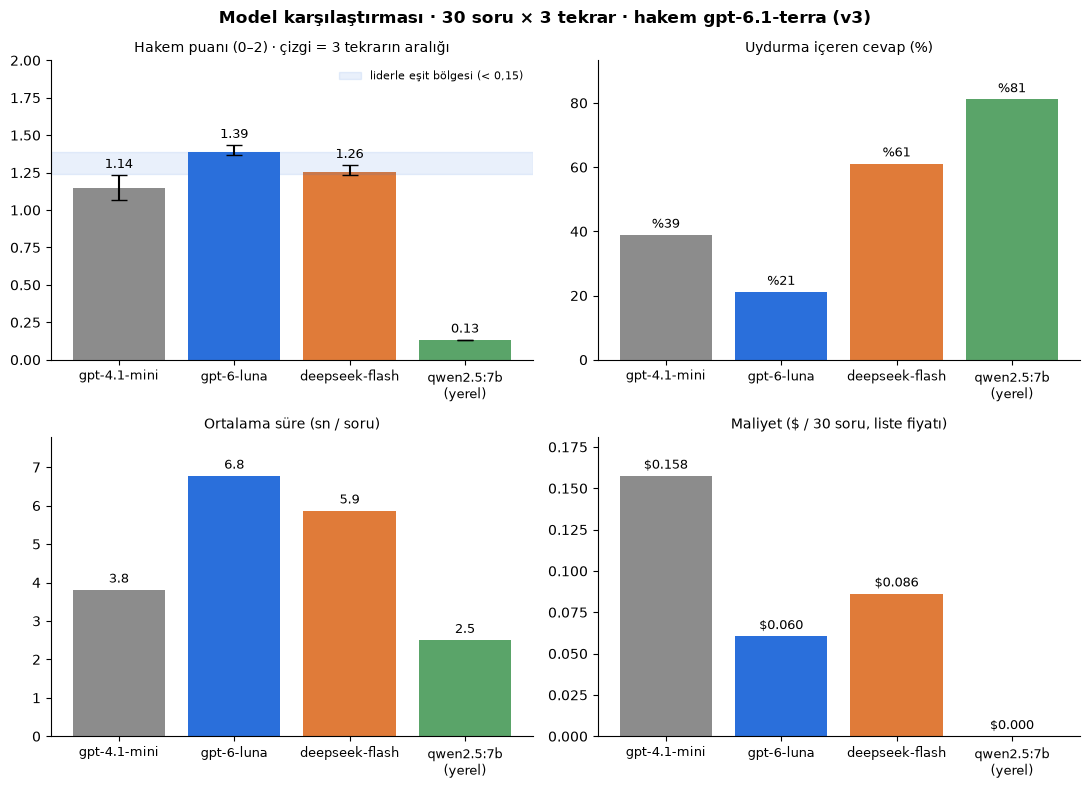

Kaydedildi: /home/kaan/steam-oyun-asistani/reports/figures/09_model_karsilastirma.png


In [5]:
# 09 · Adım 4: tabloları kaydet + karşılaştırma grafiği
import matplotlib.pyplot as plt

FIG = KOK / "reports/figures"
FIG.mkdir(parents=True, exist_ok=True)
ana.round(3).to_csv(KOK / "reports/09_ana_tablo.csv", encoding="utf-8-sig")
(m.pivot_table(index="kategori", columns="model", values="puan", aggfunc="mean")[MODELLER]
   .round(2).to_csv(KOK / "reports/09_kategori_puan.csv", encoding="utf-8-sig"))

RENK = {"gpt-4.1-mini": "#8c8c8c", "gpt-6-luna": "#2a6fdb", "deepseek-flash": "#e07b39", "qwen2.5:7b": "#5aa469"}
AD = {"gpt-4.1-mini": "gpt-4.1-mini", "gpt-6-luna": "gpt-6-luna", "deepseek-flash": "deepseek-flash", "qwen2.5:7b": "qwen2.5:7b\n(yerel)"}
x = list(range(len(MODELLER)))
renk = [RENK[k] for k in MODELLER]
hata = [(ana["puan"] - tekrar_ort.min(axis=1)).values, (tekrar_ort.max(axis=1) - ana["puan"]).values]

PANEL = [("puan", "Hakem puanı (0–2) · çizgi = 3 tekrarın aralığı", 1, "{:.2f}"),
         ("uydurma", "Uydurma içeren cevap (%)", 100, "%{:.0f}"),
         ("sure", "Ortalama süre (sn / soru)", 1, "{:.1f}"),
         ("maliyet_30_soru", "Maliyet ($ / 30 soru, liste fiyatı)", 1, "${:.3f}")]

fig, eksenler = plt.subplots(2, 2, figsize=(11, 8))
for a, (sutun, baslik, carpan, bicim) in zip(eksenler.flat, PANEL):
    deger = ana[sutun] * carpan
    cubuk = a.bar(x, deger, color=renk, yerr=hata if sutun == "puan" else None, capsize=6)
    a.bar_label(cubuk, labels=[bicim.format(v) for v in deger], padding=3, fontsize=9)
    a.set_title(baslik, fontsize=10)
    a.set_xticks(x, [AD[k] for k in MODELLER], fontsize=9)
    a.spines[["top", "right"]].set_visible(False)
    a.margins(y=0.15)
lider = ana["puan"].max()
eksenler[0, 0].axhspan(lider - 0.15, lider, color=RENK["gpt-6-luna"], alpha=0.10, label="liderle eşit bölgesi (< 0,15)")
eksenler[0, 0].set_ylim(0, 2)
eksenler[0, 0].legend(loc="upper right", fontsize=8, frameon=False)
fig.suptitle("Model karşılaştırması · 30 soru × 3 tekrar · hakem gpt-6.1-terra (v3)", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "09_model_karsilastirma.png", dpi=150, bbox_inches="tight")
plt.show()
print("Kaydedildi:", FIG / "09_model_karsilastirma.png")